# 08 · Peer norms for CITES: learned from the records being scored, or from LEMIS?

**The question.** This is S2.1 in [`SYSTEM CODE/DESIGN_QUESTIONS.md`](../DESIGN_QUESTIONS.md). Most of WildGuard's features describe a record against its peers: its quantity against the median of its peer group (genus × product group × unit), how common its route, purpose and source are for its genus (report §4.2). These peer norms have to be learned from some population. The model is trained with norms learned from LEMIS's training years. When it scores CITES, there are two choices:

- **(A) LEMIS norms:** describe a CITES record against US imports of 2000–2010.
- **(B) Norms from the records being scored:** describe it against CITES trade itself (rule D's records). This is the current design (ALIGNING §1.2, step 11), on the argument that "ten times the usual quantity for its peers" means the same thing in both datasets.

The argument has not been tested well. The earlier regional simulation (report §6.6 A) found that re-normalising on the target did not help (PR-AUC 0.528 against 0.539), but it used a single region and the test years.

**How it is tested.** CITES has no labels, so the choice is tested where labels exist: on LEMIS line items from a population the model never trained on. Their features are computed either with the training population's norms (A) or with norms learned from the target population itself, without its labels (B), which is what WildGuard would do on CITES.

**Fixed before looking:**
1. **Six test sets**, all evaluated on **2011**, the selection year (DESIGN_QUESTIONS B1); 2012–2014 are not used:
   - five regional holdouts: for each exporting region (Asia, Europe, the Americas, Africa, Oceania), train on line items exported from the other regions, 2000–2009, stop early on 2010 line items of listed species from the other regions, and score 2011 line items exported from the held-out region;
   - one time holdout: train on all regions 2000–2009, stop early on 2010, score 2011.
2. **Population:** animals with a class (ALIGNING §2.2).
3. **Model:** XGBoost with the settings of `wildguard/models.py`, three seeds, scores averaged over the seeds. The model is chosen later (DESIGN_QUESTIONS B5); this decision is rechecked with the chosen model in the transfer check (C6).
4. **Metric:** PR-AUC on target line items of species with a CITES listing in force (B4); all target line items reported alongside.
5. **Rule:** norms from the records being scored (B) are kept only if, on every one of the six test sets, the 95% paired-bootstrap interval of PR-AUC(B) − PR-AUC(A) on listed line items includes zero or lies above it. If B is significantly worse on any test set, WildGuard scores CITES with LEMIS norms (A), and ALIGNING §1.2 step 11 changes. The bootstrap resamples shipments.
6. **Reported, not deciding:** how many target line items find their peer group in each set of norms.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import eda_setup as E
import experiment_setup as X_
from wildguard.features import MIN_PEER, SHARED_FEATURES, FeatureBuilder, to_model_matrix

E.style()
t0 = time.time()
df = X_.load_lemis()
df = df[df["animal"]].reset_index(drop=True)
yr, reg = df["year"].to_numpy(), df["exporter_region"].to_numpy()
y, listed = df["label"].to_numpy(), df["sp_listed"].to_numpy()
SEEDS = (0, 1, 2)
TESTS = {f"holdout: {r}": r for r in ("Asia", "Europe", "Americas", "Africa", "Oceania")}
TESTS["time only"] = None
print(f"{len(df):,} line items of animals with a class ({time.time() - t0:.0f}s)")

5,107,119 line items of animals with a class (3s)


## 1. Train once per test set; score the target with both sets of norms

In [2]:
def peer_coverage(fb, target):
    """Share of target line items whose genus-level peer group has at least MIN_PEER records."""
    k = ["genus", "product_group", "unit_group"]
    m = target[k].merge(fb.peer_genus[k + ["q_n"]], on=k, how="left")
    return float((m["q_n"].fillna(0) >= MIN_PEER).mean())


scores, rows = {}, []
for name, r in TESTS.items():
    src = (reg != r) if r else np.ones(len(df), bool)
    tgt = ((reg == r) if r else np.ones(len(df), bool)) & (yr == 2011)
    tr, va = src & (yr <= 2009), src & (yr == 2010) & listed
    fb_a = FeatureBuilder(use_value=False).fit(df[tr])
    fb_b = FeatureBuilder(use_value=False).fit(df[tgt], vocab_from=fb_a)
    X_tr, cats = to_model_matrix(fb_a.transform(df[tr]), SHARED_FEATURES)
    X_va = to_model_matrix(fb_a.transform(df[va]), SHARED_FEATURES, cats)[0]
    target = df[tgt].reset_index(drop=True)
    X_a = to_model_matrix(fb_a.transform(target), SHARED_FEATURES, cats)[0]
    X_b = to_model_matrix(fb_b.transform(target), SHARED_FEATURES, cats)[0]
    s_a, s_b = np.zeros(len(target)), np.zeros(len(target))
    for seed in SEEDS:
        m = X_.fit_split(X_tr, y[tr], X_va, y[va], seed)
        s_a += m.predict_proba(X_a)[:, 1] / len(SEEDS)
        s_b += m.predict_proba(X_b)[:, 1] / len(SEEDS)
    scores[name] = dict(target=target, a=s_a, b=s_b)
    rows.append({"test set": name, "training line items": int(tr.sum()),
                 "target line items": len(target), "target cases": int(target.label.sum()),
                 "target listed cases": int(target.label[target.sp_listed].sum()),
                 "peer group found, LEMIS norms (A)": peer_coverage(fb_a, target),
                 "peer group found, target norms (B)": peer_coverage(fb_b, target)})
    print(f"{name}: done ({time.time() - t0:.0f}s)")
pd.DataFrame(rows).set_index("test set").style.format(
    {c: "{:.1%}" for c in ("peer group found, LEMIS norms (A)", "peer group found, target norms (B)")}
    | {c: "{:,}" for c in ("training line items", "target line items", "target cases", "target listed cases")})

holdout: Asia: done (52s)


holdout: Europe: done (130s)


holdout: Americas: done (182s)


holdout: Africa: done (270s)


holdout: Oceania: done (348s)


time only: done (449s)


,training line items,target line items,target cases,target listed cases,"peer group found, LEMIS norms (A)","peer group found, target norms (B)"
test set,,,,,,
holdout: Asia,"1,993,550","145,089","2,523",712,70.8%,81.5%
holdout: Europe,"2,614,420","81,677",948,530,91.8%,91.8%
holdout: Americas,"2,516,520","73,920","2,732",744,63.7%,76.8%
holdout: Africa,"2,731,130","43,024",480,257,89.0%,89.7%
holdout: Oceania,"3,020,775","20,794",516,149,82.8%,84.1%
time only,"3,205,852","370,113","7,294","2,417",87.2%,86.3%


## 2. PR-AUC with each set of norms

In [3]:
PAIR = [("B: target norms", "A: LEMIS norms")]
res = []
for name, s in scores.items():
    t = s["target"]
    for subset, mask in (("listed species", t.sp_listed.to_numpy()), ("all", np.ones(len(t), bool))):
        b = X_.pr_auc_bootstrap(t.label.to_numpy()[mask],
                                {"B: target norms": s["b"][mask], "A: LEMIS norms": s["a"][mask]},
                                t.shipment_id.to_numpy()[mask], PAIR)
        res.append(b.assign(**{"test set": name, "line items": subset}))
res = pd.concat(res).set_index(["line items", "test set"])[["pr_auc_b", "pr_auc_a", "difference", "low_95", "high_95"]]
res.columns = ["PR-AUC, A: LEMIS norms", "PR-AUC, B: target norms", "B − A", "95% low", "95% high"]
res.style.format("{:.3f}")

,,"PR-AUC, A: LEMIS norms","PR-AUC, B: target norms",B − A,95% low,95% high
line items,test set,,,,,
listed species,holdout: Asia,0.601,0.611,0.009,-0.001,0.020
all,holdout: Asia,0.591,0.594,0.003,-0.002,0.008
listed species,holdout: Europe,0.101,0.116,0.015,0.005,0.026
all,holdout: Europe,0.174,0.178,0.004,-0.007,0.015
listed species,holdout: Americas,0.498,0.519,0.022,0.003,0.043
all,holdout: Americas,0.612,0.571,-0.041,-0.056,-0.024
listed species,holdout: Africa,0.264,0.307,0.042,0.018,0.069
all,holdout: Africa,0.299,0.331,0.031,0.014,0.048
listed species,holdout: Oceania,0.554,0.488,-0.066,-0.105,-0.026


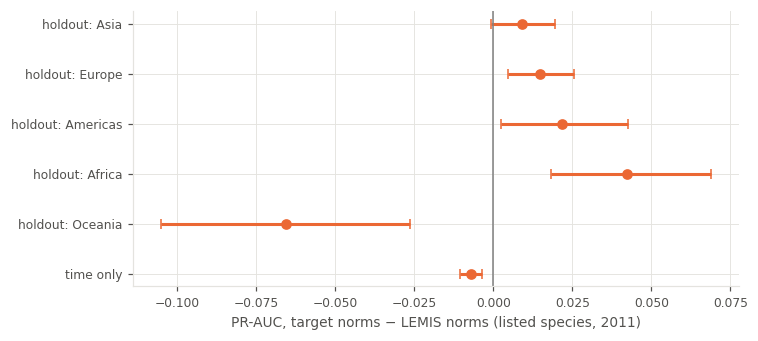

In [4]:
d = res.loc["listed species"]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(d["B − A"], range(len(d)), xerr=[d["B − A"] - d["95% low"], d["95% high"] - d["B − A"]],
            fmt="o", color=E.CITES_C, capsize=3)
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(range(len(d)), d.index)
ax.set_xlabel("PR-AUC, target norms − LEMIS norms (listed species, 2011)")
ax.invert_yaxis()
plt.tight_layout()

## 3. The rule

In [5]:
worse = d[d["95% high"] < 0].index.tolist()
KEEP_TARGET_NORMS = not worse
print("Test sets where target norms are significantly worse:", worse or "none")
print("Decision:", "norms learned from the records being scored (B) are kept"
      if KEEP_TARGET_NORMS else "CITES is scored with LEMIS norms (A); ALIGNING §1.2 step 11 changes")

Test sets where target norms are significantly worse: ['holdout: Oceania', 'time only']
Decision: CITES is scored with LEMIS norms (A); ALIGNING §1.2 step 11 changes


## Findings

| # | Finding | Consequence |
|---|---|---|
| N1 | On listed line items, norms learned from the target helped on three regional holdouts (Europe +0.015, the Americas +0.022, Africa +0.042; Asia +0.009, interval including zero) but were significantly worse on Oceania (−0.066) and on the time holdout (−0.007) | The rule fails |
| N2 | The effect is not consistent in sign: on all line items the Americas reverse (−0.041). Re-normalising on the target is not a reliable improvement, as the earlier single-region simulation also found (report §6.6 A) | — |
| N3 | Target norms find a record's genus-level peer group more often where the target trades taxa the source rarely does (Asia 81.5% against 70.8%, the Americas 76.8% against 63.7%). Records without one fall back to class-level norms | On CITES this gap may be larger; the coverage of LEMIS norms on CITES records is reported when the pipeline is rebuilt |

**Decision (S2.1):** WildGuard scores CITES records with the peer norms learned from LEMIS's training years (A), not with norms learned from CITES (B). ALIGNING §1.2 step 11 and `wildguard/cites_features.py` change accordingly. The decision is rechecked with the model Part B chooses, in the transfer check (DESIGN_QUESTIONS C6).